# 03 — Teleportación y codificación superdensa

**Curso ECCI 2026 · Computación cuántica**

En el 02 quedó establecido que un par de Bell es un objeto raro: dos qubits
perfectamente correlacionados en toda base, con pureza global 1 y pureza
local
1/2. Ahora la pregunta útil: **¿para qué sirve?**

Sirve para dos cosas, y son **duales**. Una convierte comunicación clásica
en
transmisión cuántica; la otra convierte transmisión cuántica en comunicación
clásica. Son la misma moneda vista de los dos lados, y por eso van juntas en
el mismo notebook.

| | **codificación superdensa** | **teleportación** |
|---|---|---|
| Alice y Bob comparten | 1 par de Bell | 1 par de Bell |
| Alice manda | **1 qubit** | **2 bits clásicos** |
| Bob recibe | **2 bits clásicos** de información | **1 qubit** en estado desconocido |
| sin el par de Bell | 1 qubit ⟶ 1 bit (cota de Holevo) | imposible |

La simetría es exacta: en una, el par de Bell **duplica** lo que carga un
qubit;
en la otra, permite mandar un qubit **sin mandar ningún qubit**.

Arrancamos por la superdensa, que es más corta y no necesita mediciones a
mitad de circuito.

## Preámbulo: entorno

Esta celda no hace nada en el entorno local (el env `quantum`, que ya tiene
todo instalado). Solo actúa si el notebook corre en **Google Colab**, donde
instala lo que falta.

`plotly` e `ipywidgets` vienen con Colab, así que no se instalan.

**Sobre `utils.py`:** los notebooks importan ese módulo, que en el entorno
local está en la misma carpeta. En Colab la celda lo **baja solo** de un
archivo de Drive compartido como "cualquiera con el link puede ver", así que
funciona para cualquiera que abra el notebook sin que tenga que autenticarse.

Dos detalles de esa descarga:

- se usa el endpoint `drive.usercontent.google.com`, porque la URL clásica
  `uc?export=download` devuelve la página de aviso de antivirus en vez del
  archivo;
- solo baja si `utils` no está ya disponible, de modo que una **subida manual
  al panel de archivos tiene prioridad** sobre la copia de Drive.

Si el archivo de Drive se actualiza con *Administrar versiones*, el ID y el
link se mantienen, y los notebooks siguen apuntando al lugar correcto.

In [1]:
import importlib.util
import sys

try:                      # find_spec("google.colab") falla si no existe el padre
    import google.colab   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !pip install qiskit
    !pip install qiskit-ibm-runtime
    !pip install qiskit_aer
    !pip install pylatexenc

    # utils.py desde Drive, compartido como "cualquiera con el link puede ver".
    # Se usa el endpoint drive.usercontent, que entrega el archivo directo; la
    # URL clásica uc?export=download devuelve la página de aviso de antivirus.
    # Solo se baja si no está ya presente, así una subida manual tiene prioridad.
    UTILS_ID = "1_VyKXtDMVqnJHcGepeARhoEY4tikLSDg"
    if importlib.util.find_spec("utils") is None:
        !wget -q -O utils.py "https://drive.usercontent.google.com/download?id=$UTILS_ID&export=download&confirm=t"
        importlib.invalidate_caches()
        if importlib.util.find_spec("utils") is None:
            print("No se pudo bajar utils.py: subirlo a mano desde el panel de archivos.")
        else:
            print("utils.py descargado de Drive")
else:
    print("entorno local: no hay nada que instalar")

try:
    import utils
    print(f"utils.py versión {utils.__version__}")
except ImportError:
    print("utils.py todavía no está disponible")

entorno local: no hay nada que instalar


utils.py versión 2026-09-19


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, transpile
from qiskit.quantum_info import (DensityMatrix, Pauli, Statevector, partial_trace,
                                 state_fidelity)
from qiskit.visualization import plot_state_qsphere
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeFez

import plotly.io as pio

import utils

utils.estilo()
pio.renderers.default = "plotly_mimetype"
fez = FakeFez()
SHOTS = 8192
MARCAS = "①②③④⑤⑥⑦⑧⑨"


def marca(qc, n):
    """Barrera numerada: el punto donde el texto calcula el estado."""
    qc.barrier(label=MARCAS[n - 1])
    return qc


print("listo")

listo


## Autenticación (opcional, y en memoria)

La API key se tipea a mano y vive solo en la memoria de este kernel. Sin
correr esta celda, el notebook entero funciona en simulador.

In [3]:
from getpass import getpass

from qiskit_ibm_runtime import QiskitRuntimeService

CRN = "crn:v1:bluemix:public:quantum-computing:us-east:a/1a958fc8c19b451ba71d1d0d94d52a44:9153727a-cc43-46be-a974-dfe1f29b4bcb::"

AUTENTICAR = False

service = None
if AUTENTICAR:
    service = QiskitRuntimeService(channel="ibm_cloud",
                                   token=getpass("API key: "),
                                   instance=CRN)
    print([b.name for b in service.backends()])
else:
    print("sin autenticar — el notebook corre entero en simulador")

sin autenticar — el notebook corre entero en simulador


---
# 1. Codificación superdensa

## 1.1 La idea

Alice quiere mandarle a Bob **dos bits** clásicos: `00`, `01`, `10` u `11`.
Solo puede mandarle **un qubit**.

Sin ayuda esto es imposible. El **teorema de Holevo** dice que un qubit no
puede transportar más de **un** bit clásico de información accesible, por
más
ingenio que uno le ponga a la codificación. Un qubit tiene infinitos estados
posibles, pero la medición solo devuelve un resultado, y la cota es dura.

Con un par de Bell compartido de antemano, se puede. Y la razón cabe en dos
renglones:

**(a) Los cuatro estados de Bell son ortogonales entre sí.** Forman una
base,
así que una medición apropiada los distingue con **certeza total** — no hay
ambigüedad, no hay probabilidades.

**(b) Se puede saltar entre los cuatro tocando un solo qubit.** Alice aplica
una compuerta a **su mitad** y el par entero cambia de estado de Bell:

$$\begin{aligned}
(I \otimes I)\,|\Phi^+\rangle &= |\Phi^+\rangle & &\text{mensaje } 00\\
(X \otimes I)\,|\Phi^+\rangle &= |\Psi^+\rangle & &\text{mensaje } 01\\
(Z \otimes I)\,|\Phi^+\rangle &= |\Phi^-\rangle & &\text{mensaje } 10\\
(ZX \otimes I)\,|\Phi^+\rangle &= |\Psi^-\rangle & &\text{mensaje } 11
\end{aligned}$$

Ese es todo el truco, y es más raro de lo que parece: Alice, tocando
**solamente su qubit**, mueve el estado conjunto entre cuatro estados
globalmente distinguibles. La información no está en su qubit: está en la
**relación** entre los dos. Por eso cuando Bob junta los dos qubits, puede
leer los dos bits.

Mensaje 11: Alice aplica X y después Z sobre su qubit


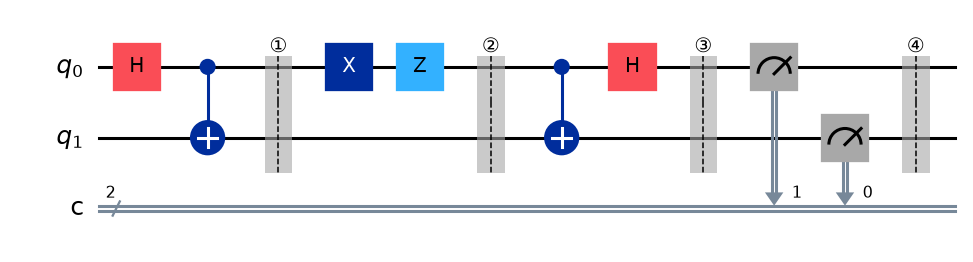

In [4]:
def superdensa(b1: int, b0: int, medir=True) -> QuantumCircuit:
    """Alice (qubit 0) le manda dos bits a Bob (qubit 1).

    ATENCIÓN con los bits clásicos: los cruzamos a propósito (qubit 0 -> c1,
    qubit 1 -> c0) para que la cadena de counts se lea directamente como el
    mensaje 'b1b0'. Sin ese cruce, el little-endian de Qiskit la devuelve dada
    vuelta y uno pierde media hora.
    """
    qc = QuantumCircuit(2, 2) if medir else QuantumCircuit(2)

    qc.h(0); qc.cx(0, 1)          # el par de Bell, repartido antes de todo
    marca(qc, 1)

    if b0:                        # Alice codifica, tocando SOLO su qubit
        qc.x(0)
    if b1:
        qc.z(0)
    marca(qc, 2)                  # acá Alice manda su qubit por el canal

    qc.cx(0, 1); qc.h(0)          # Bob mide en la base de Bell
    marca(qc, 3)

    if medir:
        qc.measure(0, 1)
        qc.measure(1, 0)
        marca(qc, 4)
    return qc


print("Mensaje 11: Alice aplica X y después Z sobre su qubit")
display(superdensa(1, 1).draw("mpl", style="iqp", fold=-1))

### La cuenta, etapa por etapa (mensaje `11`)

**①** El par repartido:
$$|\psi_1\rangle = |\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt2}.$$
Alice tiene el qubit 0, Bob el 1, y pueden estar a años luz.

**②** Dado que Alice aplica $X$ y luego $Z$ **a su qubit solamente**:
$$X_0|\Phi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt2} = |\Psi^+\rangle,
  \qquad
  Z_0|\Psi^+\rangle = \frac{|01\rangle - |10\rangle}{\sqrt2} =
    |\Psi^-\rangle.$$
El estado conjunto es ahora un estado de Bell **distinto y ortogonal** al de
partida. Acá Alice manda su qubit físico a Bob.

**③** Dado que Bob aplica CNOT (control 0, blanco 1) y después $H$ al qubit
0
—que es exactamente la inversa del circuito que crea estados de Bell— la
base
de Bell se convierte en la base computacional:
$$|\Phi^+\rangle \to |00\rangle,\quad |\Psi^+\rangle \to |01\rangle,\quad
  |\Phi^-\rangle \to |10\rangle,\quad |\Psi^-\rangle \to |11\rangle.$$
Para el mensaje `11`, el estado en ③ es $|11\rangle$ (salvo un signo global
que no se mide).

**④** Dado que Bob mide en la base computacional: obtiene `11` con
probabilidad **1**. Sin ruido, no se equivoca nunca.

### Los cuatro mensajes en la Q-sphere

Acá se ve que los cuatro estados codificados son realmente distintos. Miremos
**dónde** están los puntos y **de qué color**: $|\Phi^\pm\rangle$ viven en
los
polos y se distinguen solo por el color (la fase); $|\Psi^\pm\rangle$ viven
en
el ecuador.

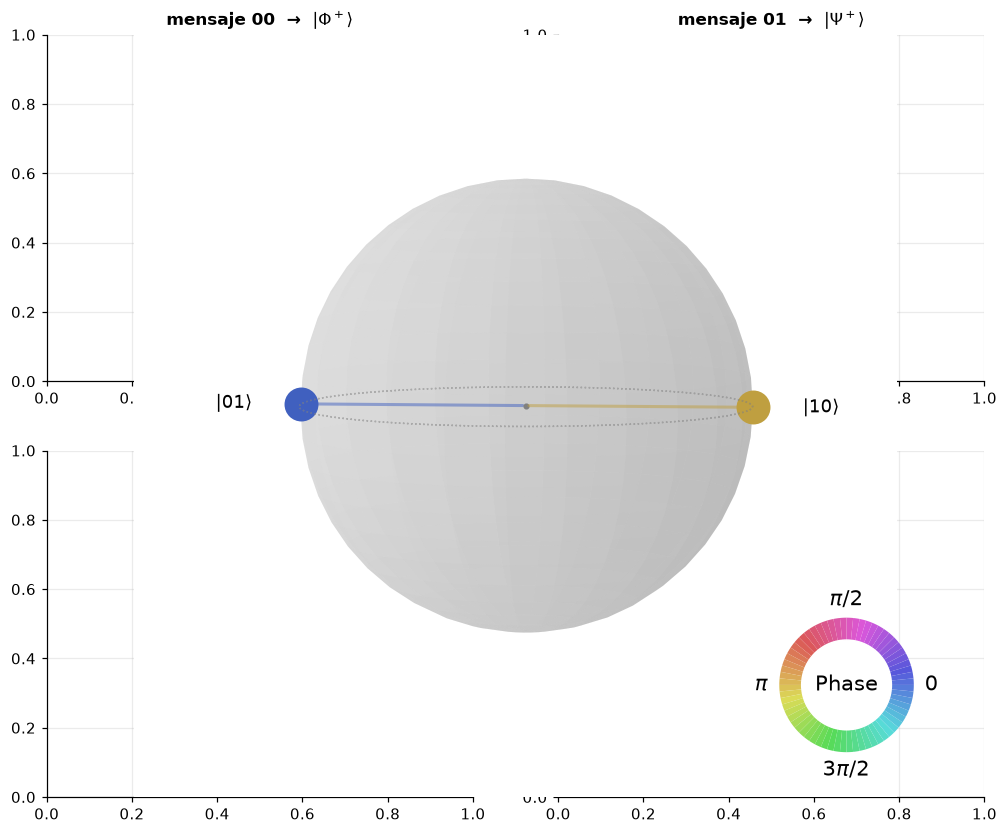

In [5]:
fig = plt.figure(figsize=(11, 9))
nombres_bell = {(0, 0): r"$|\Phi^+\rangle$", (0, 1): r"$|\Psi^+\rangle$",
                (1, 0): r"$|\Phi^-\rangle$", (1, 1): r"$|\Psi^-\rangle$"}
for i, (b1, b0) in enumerate([(0, 0), (0, 1), (1, 0), (1, 1)]):
    qc = QuantumCircuit(2)
    qc.h(0); qc.cx(0, 1)
    if b0:
        qc.x(0)
    if b1:
        qc.z(0)
    ax = fig.add_subplot(2, 2, i + 1)
    plot_state_qsphere(Statevector(qc), ax=ax, show_state_labels=True)
    ax.set_title(f"mensaje {b1}{b0}  →  {nombres_bell[(b1, b0)]}", fontsize=11)
plt.show()

### Lo que NO cambia: por qué esto no manda información instantánea

Acá hay una trampa conceptual, y es mejor desactivarla antes de que
aparezca.
Alice toca su qubit y el estado **conjunto** cambia. ¿No se entera Bob al
instante?

**No.** Y los discos por qubit lo muestran sin necesidad de argumentar.

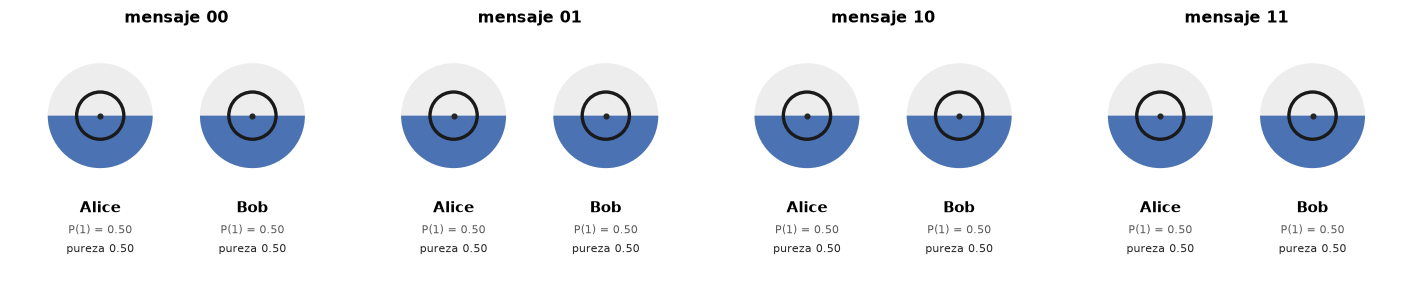

Estado reducido del qubit de Bob, para cada mensaje:
  mensaje 00:  rho_Bob = [[(0.5+0j), 0j], [0j, (0.5+0j)]]
  mensaje 01:  rho_Bob = [[(0.5+0j), 0j], [0j, (0.5+0j)]]
  mensaje 10:  rho_Bob = [[(0.5+0j), 0j], [0j, (0.5+0j)]]
  mensaje 11:  rho_Bob = [[(0.5+0j), 0j], [0j, (0.5+0j)]]

¿son todos idénticos? True


In [6]:
fig, ejes = plt.subplots(1, 4, figsize=(13, 2.5))
for ax, (b1, b0) in zip(ejes, [(0, 0), (0, 1), (1, 0), (1, 1)]):
    qc = QuantumCircuit(2)
    qc.h(0); qc.cx(0, 1)
    if b0:
        qc.x(0)
    if b1:
        qc.z(0)
    utils.discos_qubits(Statevector(qc), ax=ax, etiquetas=["Alice", "Bob"],
                        titulo=f"mensaje {b1}{b0}")
utils.layout(fig)
plt.show()

rho_bob = {}
for b1, b0 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    qc = QuantumCircuit(2)
    qc.h(0); qc.cx(0, 1)
    if b0:
        qc.x(0)
    if b1:
        qc.z(0)
    rho_bob[(b1, b0)] = partial_trace(DensityMatrix(Statevector(qc)), [0])

print("Estado reducido del qubit de Bob, para cada mensaje:")
for k, r in rho_bob.items():
    print(f"  mensaje {k[0]}{k[1]}:  rho_Bob = {np.round(r.data, 4).tolist()}")
base = rho_bob[(0, 0)]
print(f"\n¿son todos idénticos? "
      f"{all(np.allclose(r.data, base.data) for r in rho_bob.values())}")

**Los cuatro discos de Bob son idénticos**, y su matriz densidad es $I/2$ en
los cuatro casos. Haga Alice lo que haga, Bob no ve **ninguna** diferencia
mirando su qubit: sigue dando 50/50 en toda base.

La información aparece recién cuando los dos qubits se juntan. Y juntarlos
requiere **mandar físicamente el qubit de Alice**, que viaja a la velocidad
de
la luz como cualquier cosa. Por eso no hay comunicación superlumínica: el
canal cuántico es el qubit que viaja, y el par de Bell solo lo hace rendir
el
doble.

Esto es un teorema general, el **teorema de no-señalización**: ninguna
operación local sobre una parte de un estado entrelazado cambia el estado
reducido de la otra parte. Los discos de arriba son su demostración visual.

### Corriendo los cuatro mensajes

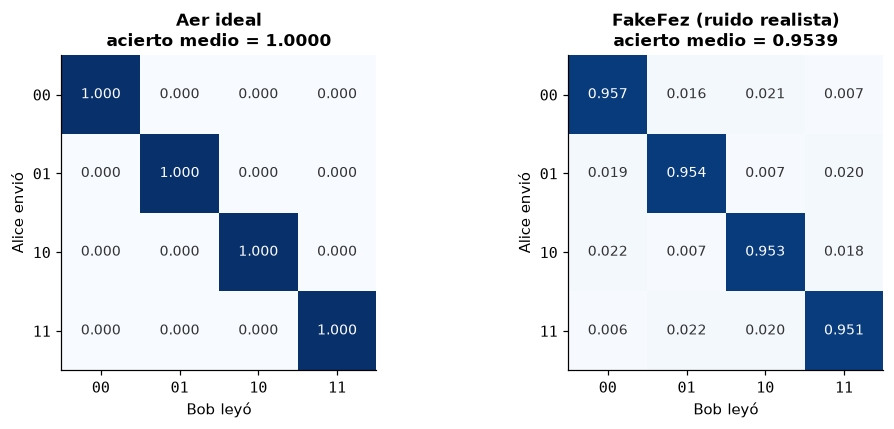

bits transmitidos por qubit enviado, ideal   : 2.0000
bits transmitidos por qubit enviado, FakeFez : 1.9079
cota de Holevo sin entrelazamiento previo    : 1.0000


In [7]:
mensajes = [(0, 0), (0, 1), (1, 0), (1, 1)]
circuitos_sd = [superdensa(b1, b0) for b1, b0 in mensajes]
c_sd_ideal = utils.correr_ideal(circuitos_sd, shots=SHOTS)
c_sd_ruido = utils.correr_ruidoso(circuitos_sd, backend_falso=fez, shots=SHOTS)


def matriz_confusion(lista_counts, mensajes=mensajes):
    """Fila = mensaje enviado, columna = mensaje leído."""
    claves = [f"{b1}{b0}" for b1, b0 in mensajes]
    M = np.zeros((len(mensajes), len(claves)))
    for i, counts in enumerate(lista_counts):
        n = sum(counts.values())
        for j, k in enumerate(claves):
            M[i, j] = counts.get(k, 0) / n
    return M, claves


def dibujar_confusion(M, claves, ax, titulo):
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(claves)):
        for j in range(len(claves)):
            ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if M[i, j] > 0.55 else "0.2")
    ax.set_xticks(range(len(claves))); ax.set_xticklabels(claves, family="monospace")
    ax.set_yticks(range(len(claves))); ax.set_yticklabels(claves, family="monospace")
    ax.set_xlabel("Bob leyó"); ax.set_ylabel("Alice envió")
    ax.grid(False)
    ax.set_title(f"{titulo}\nacierto medio = {np.trace(M) / len(claves):.4f}")
    return im


M_ideal, claves = matriz_confusion(c_sd_ideal)
M_ruido, _ = matriz_confusion(c_sd_ruido)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4))
dibujar_confusion(M_ideal, claves, ax1, "Aer ideal")
dibujar_confusion(M_ruido, claves, ax2, "FakeFez (ruido realista)")
utils.layout(fig)
plt.show()

bits_por_qubit_ideal = 2 * np.trace(M_ideal) / 4
bits_por_qubit_ruido = 2 * np.trace(M_ruido) / 4
print(f"bits transmitidos por qubit enviado, ideal   : {bits_por_qubit_ideal:.4f}")
print(f"bits transmitidos por qubit enviado, FakeFez : {bits_por_qubit_ruido:.4f}")
print("cota de Holevo sin entrelazamiento previo    : 1.0000")

**La diagonal es el protocolo funcionando.** Ideal: 1.000 en los cuatro
casos,
sin ambigüedad — porque los cuatro estados de Bell son ortogonales y una
base
ortogonal se distingue con certeza.

Con ruido la diagonal baja y aparecen errores fuera de ella, y el patrón
dice cuáles:
los errores no son uniformes, porque confundir $|\Phi^+\rangle$ con
$|\Phi^-\rangle$ (un error de **fase**) es más fácil que confundirlo con
$|\Psi^+\rangle$ (un error de **bit**). El patrón de la matriz dice qué tipo
de ruido domina en el chip.

Y el número que cierra la sección: **más de 1 bit por qubit enviado**, que
es
justo lo que Holevo prohíbe sin entrelazamiento previo. El par de Bell no
transmite información por sí mismo —eso lo vimos con los discos— pero cambia
lo que un qubit es capaz de cargar.

---
# 2. Teleportación

## 2.1 El problema

Ahora al revés. Alice tiene un qubit en un estado
$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ que **no conoce**, y
quiere
que Bob lo tenga. Solo puede mandarle **bits clásicos**.

Los tres obstáculos, para que se vea la magnitud del problema:

1. **No puede medirlo.** Una medición devuelve un bit y destruye el resto:
   $\alpha$ y $\beta$ son números complejos continuos, imposibles de
   reconstruir de un `0` o un `1`.
2. **No puede clonarlo.** El **teorema de no-clonación** prohíbe una máquina
   que haga $|\psi\rangle \to |\psi\rangle|\psi\rangle$ para todo $\psi$. La
   prueba es de dos líneas: tal máquina sería lineal, y la linealidad falla
   para superposiciones.
3. **No puede describirlo.** Ni siquiera conociendo $\alpha$ y $\beta$
   exactamente podría mandarlos: son números reales, infinitos bits.

Y sin embargo, con un par de Bell previo, **dos bits alcanzan**.

## 2.2 El álgebra: dónde estaba escondido el estado

El sistema completo son tres qubits: el de Alice con $|\psi\rangle$ (qubit
0),
y el par de Bell (qubits 1 de Alice y 2 de Bob):

$$|\Psi\rangle = |\psi\rangle_0 \otimes |\Phi^+\rangle_{12}
  = (\alpha|0\rangle + \beta|1\rangle)_0 \otimes
    \frac{|00\rangle + |11\rangle}{\sqrt2}.$$

El paso clave es **reagrupar**: en vez de escribirlo en la base
computacional,
lo escribimos usando la base de Bell **de los dos qubits de Alice** (el 0 y
el
1). Es puro álgebra, no pasa nada físico:

$$|\Psi\rangle = \frac{1}{2}\Big[\;
  |\Phi^+\rangle_{01}\,(\alpha|0\rangle + \beta|1\rangle)_2
+ |\Phi^-\rangle_{01}\,(\alpha|0\rangle - \beta|1\rangle)_2$$
$$+\; |\Psi^+\rangle_{01}\,(\alpha|1\rangle + \beta|0\rangle)_2
+ |\Psi^-\rangle_{01}\,(\alpha|1\rangle - \beta|0\rangle)_2 \;\Big]$$

**Miremos el qubit de Bob en los cuatro términos.** En todos aparece
$|\psi\rangle$, apenas deformado:

| si Alice mide | el qubit de Bob queda en | Bob corrige con |
|---|---|---|
| $\|\Phi^+\rangle$ → `00` | $\alpha\|0\rangle + \beta\|1\rangle = \|\psi\rangle$ | nada |
| $\|\Phi^-\rangle$ → `01` | $\alpha\|0\rangle - \beta\|1\rangle$ | $Z$ |
| $\|\Psi^+\rangle$ → `10` | $\alpha\|1\rangle + \beta\|0\rangle$ | $X$ |
| $\|\Psi^-\rangle$ → `11` | $\alpha\|1\rangle - \beta\|0\rangle$ | $XZ$ |

**El estado ya está del lado de Bob en los cuatro casos.** Lo único que
falta
es saber *cuál* de los cuatro, y eso son exactamente **dos bits**.

Los cuatro términos tienen coeficiente $1/2$, así que las cuatro ramas salen
con probabilidad $1/4$ cada una — **independientemente de $\alpha$ y
$\beta$**. Ese detalle es el que garantiza el no-señalizado: el resultado de
Alice no dice nada sobre el estado, así que Bob, sin los bits, no tiene
nada.

Teleportación con corrección dinámica (if_test):


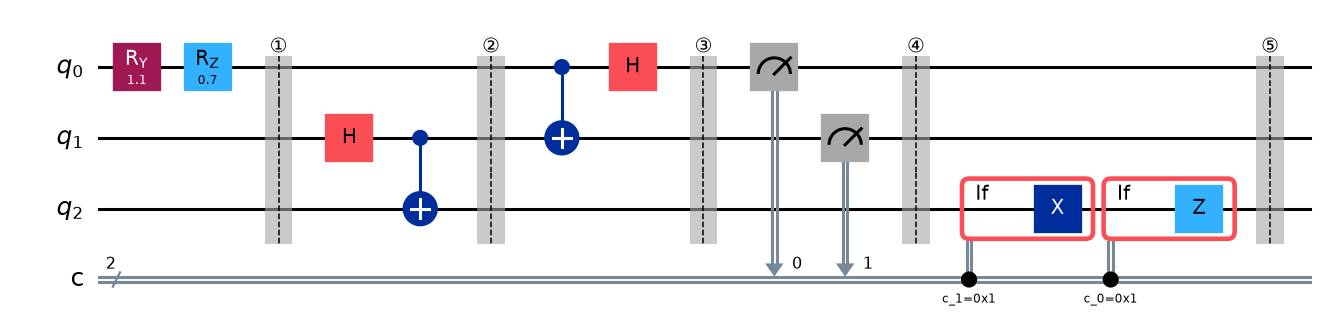

In [8]:
def teleportacion(theta, phi, corregir=True, diferida=False,
                  tomografia=None) -> QuantumCircuit:
    """Teletransporta Ry(theta)Rz(phi)|0> del qubit 0 al qubit 2.

    corregir=False  : se saltea la corrección, para ver las cuatro ramas crudas.
    diferida=True   : usa CX/CZ clásicamente controladas por el qubit, en vez de
                      if_test. Es la versión 'sin circuitos dinámicos'.
    tomografia      : 'X', 'Y' o 'Z' para medir el qubit de Bob en esa base.
    """
    qc = QuantumCircuit(3, 3 if tomografia else 2)

    qc.ry(theta, 0); qc.rz(phi, 0)     # el estado a teletransportar
    marca(qc, 1)

    qc.h(1); qc.cx(1, 2)               # el par de Bell, repartido de antemano
    marca(qc, 2)

    qc.cx(0, 1)                        # Alice mide en la base de Bell:
    qc.h(0)                            # CNOT + H convierte Bell -> computacional
    marca(qc, 3)

    if diferida:
        # Sin mediciones intermedias: las correcciones se hacen con compuertas
        # cuánticas controladas. NO es teleportación de verdad (los qubits
        # siguen juntos), pero da el mismo estado final y sirve para comparar.
        qc.cx(1, 2)
        qc.cz(0, 2)
        marca(qc, 4)
        qc.measure(0, 0); qc.measure(1, 1)
    else:
        qc.measure(0, 0); qc.measure(1, 1)   # los dos bits clásicos
        marca(qc, 4)
        if corregir:
            with qc.if_test((qc.clbits[1], 1)):   # bit de Alice del par
                qc.x(2)
            with qc.if_test((qc.clbits[0], 1)):   # bit del qubit teletransportado
                qc.z(2)
            marca(qc, 5)

    if tomografia:
        if tomografia == "X":
            qc.h(2)
        elif tomografia == "Y":
            qc.sdg(2); qc.h(2)
        qc.measure(2, 2)
        marca(qc, 6)
    return qc


THETA, PHI = 1.1, 0.7      # un estado cualquiera, ni cardinal ni simétrico
print("Teleportación con corrección dinámica (if_test):")
display(teleportacion(THETA, PHI).draw("mpl", style="iqp", fold=-1))

### La cuenta, etapa por etapa

**①** $|\Psi_1\rangle = |\psi\rangle_0 \otimes |00\rangle_{12}$. El estado a
teletransportar existe, y está **en el qubit 0**.

**②** Dado que se aplica $H$ al qubit 1 y CNOT(1→2):
$$|\Psi_2\rangle = |\psi\rangle_0 \otimes |\Phi^+\rangle_{12}.$$
Acá Alice y Bob se separan; el qubit 2 se va con Bob.

**③** Dado que Alice aplica CNOT(0→1) y $H$ al qubit 0 — que es la inversa
del
preparador de Bell, y por lo tanto **rota la base de Bell a la
computacional** — la expansión de arriba queda escrita como
$$|\Psi_3\rangle = \tfrac12\big[\,|00\rangle_{01}|\psi\rangle_2
 + |01\rangle_{01}Z|\psi\rangle_2
 + |10\rangle_{01}X|\psi\rangle_2
 + |11\rangle_{01}XZ|\psi\rangle_2 \,\big].$$
**Nada se movió todavía.** Es la misma cuenta del §2.2, con los nombres
cambiados por la rotación de base.

**④** Dado que Alice mide sus dos qubits: cae una de las cuatro ramas, cada
una con probabilidad $1/4$. El qubit de Alice **ya no tiene**
$|\psi\rangle$:
quedó en $|0\rangle$ o $|1\rangle$. Bob tiene $|\psi\rangle$ deformado por
una
de las cuatro compuertas, y no sabe cuál.

**⑤** Dado que Alice le manda los dos bits por teléfono y Bob aplica
$X^{c_1}Z^{c_0}$: las cuatro deformaciones se deshacen —porque $X$ y $Z$ son
sus propias inversas— y Bob queda con $|\psi\rangle$ exacto.

### Las cuatro ramas, antes de corregir

Esto es lo que más cuesta creer, así que hay que verlo. Corremos la
teleportación **sin la corrección** y separamos el estado de Bob según lo
que
midió Alice. Aer puede guardar una matriz densidad por rama clásica.

In [9]:
sim_dm = AerSimulator(method="density_matrix")

qc_ramas = teleportacion(THETA, PHI, corregir=False)
qc_ramas.save_density_matrix(qubits=[2], label="bob", conditional=True)
ramas = sim_dm.run(qc_ramas, shots=16384).result().data(0)["bob"]

qc_obj = QuantumCircuit(1)
qc_obj.ry(THETA, 0); qc_obj.rz(PHI, 0)
objetivo = DensityMatrix(Statevector(qc_obj))
r_objetivo = utils.bloch_de_estado(objetivo)

correcciones = {"0x0": "nada", "0x1": "Z", "0x2": "X", "0x3": "XZ"}
vectores = {"original de Alice": r_objetivo}
print(f"{'rama c1c0':>10}  {'fidelidad':>10}  {'corrección':>11}")
for clave in ("0x0", "0x1", "0x2", "0x3"):
    rho = DensityMatrix(np.asarray(ramas[clave]))
    f = state_fidelity(rho, objetivo)
    bits = format(int(clave, 16), "02b")
    vectores[f"rama {bits} (F={f:.2f})"] = utils.bloch_de_estado(rho)
    print(f"{bits:>10}  {f:>10.4f}  {correcciones[clave]:>11}")

utils.bloch_plotly(vectores, titulo="Bob SIN corregir: cuatro ramas, cuatro estados",
                   tamano=520).show()

 rama c1c0   fidelidad   corrección
        00      1.0000         nada
        01      0.2057            Z
        10      0.4646            X
        11      0.3296           XZ


**Cuatro vectores distintos, y ninguno coincide con el original salvo la
rama
`00`.** Pero miremos bien: no son cuatro estados al azar. Cada uno es el
original
reflejado por una Pauli — $Z$ lo espeja sobre el eje $z$, $X$ sobre el eje
$x$. Todos tienen la **misma longitud** que el original: son puros, no están
degradados. Solo están *rotados*, y de una forma que Bob puede deshacer si
sabe cuál.

**Y acá está la clave del no-señalizado.** Si Bob no recibe los bits, su
estado es el promedio de las cuatro ramas con peso $1/4$ cada una. Ese
promedio es exactamente $I/2$: el centro de la esfera, ninguna información.

In [10]:
# Promediar las cuatro ramas con peso 1/4. Se suman los arrays y recién ahí se
# arma la DensityMatrix: sum() arranca en el entero 0 y DensityMatrix no sabe
# sumarse a un entero.
promedio = DensityMatrix(sum(np.asarray(ramas[k]) for k in ramas) / len(ramas))
r_prom = utils.bloch_de_estado(promedio)
print("Promedio de las cuatro ramas (lo que Bob tiene antes de recibir los bits):")
print(np.round(promedio.data, 4))
print(f"\nvector de Bloch: {np.round(r_prom, 4)}   |r| = {np.linalg.norm(r_prom):.4f}")
print(f"fidelidad con el original: {state_fidelity(promedio, objetivo):.4f}")
print("\n-> I/2, el centro de la esfera. Bob no tiene NADA hasta que llegan los bits,")
print("   y los bits viajan por un canal clásico, a la velocidad de la luz.")

Promedio de las cuatro ramas (lo que Bob tiene antes de recibir los bits):
[[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]

vector de Bloch: [ 0.  0. -0.]   |r| = 0.0000
fidelidad con el original: 0.5000

-> I/2, el centro de la esfera. Bob no tiene NADA hasta que llegan los bits,
   y los bits viajan por un canal clásico, a la velocidad de la luz.


### Con la corrección puesta

Ahora las cuatro ramas tienen que colapsar sobre un solo punto: el original.

In [11]:
qc_ok = teleportacion(THETA, PHI, corregir=True)
qc_ok.save_density_matrix(qubits=[2], label="bob", conditional=True)
ramas_ok = sim_dm.run(qc_ok, shots=16384).result().data(0)["bob"]

vectores_ok = {"original de Alice": r_objetivo}
print(f"{'rama c1c0':>10}  {'fidelidad':>10}")
for clave in sorted(ramas_ok):
    rho = DensityMatrix(np.asarray(ramas_ok[clave]))
    f = state_fidelity(rho, objetivo)
    bits = format(int(clave, 16), "02b")
    vectores_ok[f"rama {bits} (F={f:.3f})"] = utils.bloch_de_estado(rho)
    print(f"{bits:>10}  {f:>10.4f}")

utils.bloch_plotly(vectores_ok,
                   titulo="Bob CON corrección: las cuatro ramas se superponen",
                   tamano=520).show()

 rama c1c0   fidelidad
        00      1.0000
        01      1.0000
        10      1.0000
        11      1.0000


Las cinco flechas están una encima de la otra. Eso es la teleportación
funcionando: sin importar qué midió Alice, después de corregir Bob tiene el
estado original.

### ¿Funciona para cualquier estado?

El protocolo no depende de $\alpha$ y $\beta$ — de hecho Alice **nunca los
conoce**. Barremos la esfera entera para comprobarlo.

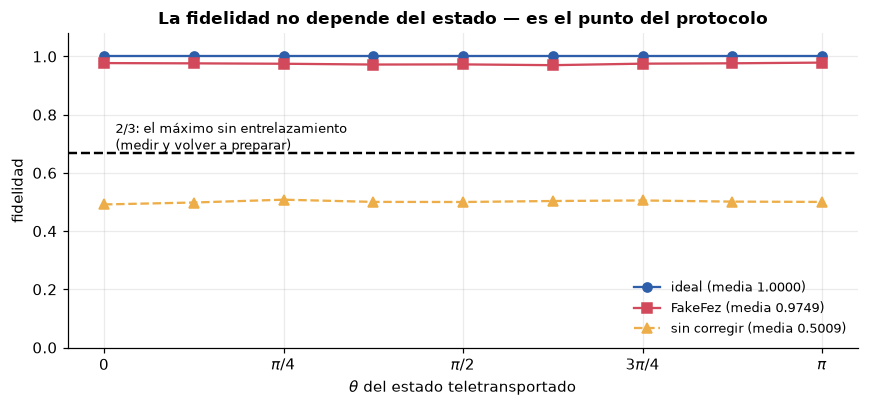

In [12]:
# Para la versión ruidosa transpilamos SOLO a la base de compuertas del modelo
# de ruido, sin coupling map. Dos razones: el circuito se queda en 3 qubits (si
# lo mapeáramos al chip de 156, la matriz densidad sería de 4^156 y no existe
# computadora que la aguante), y aun así cada compuerta arrastra los errores
# reales de FakeFez. Lo que se pierde es el costo de los SWAPs, así que esta
# fidelidad es un poco optimista respecto del chip.
NM_FEZ = NoiseModel.from_backend(fez)
SIM_RUIDO = AerSimulator(method="density_matrix", noise_model=NM_FEZ)


def fidelidad_teleportada(theta, phi, ruido=False, corregir=True, shots=8192):
    qc = teleportacion(theta, phi, corregir=corregir)
    if not ruido:
        qc.save_density_matrix(qubits=[2], label="bob")
        rho = sim_dm.run(qc, shots=shots).result().data(0)["bob"]
    else:
        tq = transpile(qc, basis_gates=NM_FEZ.basis_gates, optimization_level=1)
        tq.save_density_matrix(qubits=[2], label="bob")
        rho = SIM_RUIDO.run(tq, shots=shots).result().data(0)["bob"]
    q = QuantumCircuit(1); q.ry(theta, 0); q.rz(phi, 0)
    return state_fidelity(DensityMatrix(np.asarray(rho)), DensityMatrix(Statevector(q)))


thetas = np.linspace(0, np.pi, 9)
fid_ideal = [fidelidad_teleportada(t, PHI) for t in thetas]
fid_sin = [fidelidad_teleportada(t, PHI, corregir=False) for t in thetas]
fid_ruido = [fidelidad_teleportada(t, PHI, ruido=True) for t in thetas]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(thetas, fid_ideal, "o-", ms=6, color=utils.COLOR_IDEAL,
        label=f"ideal (media {np.mean(fid_ideal):.4f})")
ax.plot(thetas, fid_ruido, "s-", ms=6, color=utils.COLOR_RUIDO,
        label=f"FakeFez (media {np.mean(fid_ruido):.4f})")
ax.plot(thetas, fid_sin, "^--", ms=6, color=utils.PALETA[3],
        label=f"sin corregir (media {np.mean(fid_sin):.4f})")
ax.axhline(2 / 3, color="k", lw=1.6, ls="--")
ax.text(0.05, 0.68, "2/3: el máximo sin entrelazamiento\n(medir y volver a preparar)",
        fontsize=8.5)
ax.set_xlabel(r"$\theta$ del estado teletransportado")
ax.set_ylabel("fidelidad")
ax.set_ylim(0, 1.08)
ax.set_xticks(np.linspace(0, np.pi, 5))
ax.set_xticklabels(["0", r"$\pi/4$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$"])
ax.set_title("La fidelidad no depende del estado — es el punto del protocolo")
ax.legend(fontsize=8.5, loc="lower right")
utils.layout(fig)
plt.show()

**La línea en 2/3 es la que le da sentido al experimento.** Si Alice no
tuviera el par de Bell y hiciera lo mejor posible con recursos clásicos
—medir el qubit en una base al azar, mandarle el resultado a Bob, y que Bob
prepare ese estado— la fidelidad media sobre todos los estados posibles
sería
$2/3$. Ese es el **límite clásico de la teleportación**.

Superarlo es la prueba de que hubo entrelazamiento en el medio. El simulador
ideal da 1.000; con ruido de FakeFez baja, pero queda muy por encima de 2/3.
Y la curva "sin corregir" se queda en $\sim 0.5$, que es lo que vale
adivinar.

### Dinámica contra diferida

Hay dos formas de implementar la corrección, y la diferencia importa en
hardware:

- **Dinámica** (`if_test`): Alice mide de verdad, los bits salen al mundo
   clásico, y Bob aplica la compuerta condicionada al valor leído. Es el
   protocolo real. En Heron funciona, pero la medición a mitad de circuito
   dura microsegundos durante los cuales el qubit de Bob se decohera.
- **Diferida**: se reemplazan las correcciones clásicas por CNOT y CZ
   cuánticas. Da el mismo estado final y evita la medición intermedia, pero
   **no es teleportación**: los tres qubits siguen en el mismo chip,
   interactuando. Sirve como control, no como demostración.

variante                            fidelidad  profundidad
dinámica (if_test)                     1.0000            9
diferida (CX/CZ)                       1.0000            9


dinámica + ruido FakeFez               0.9747


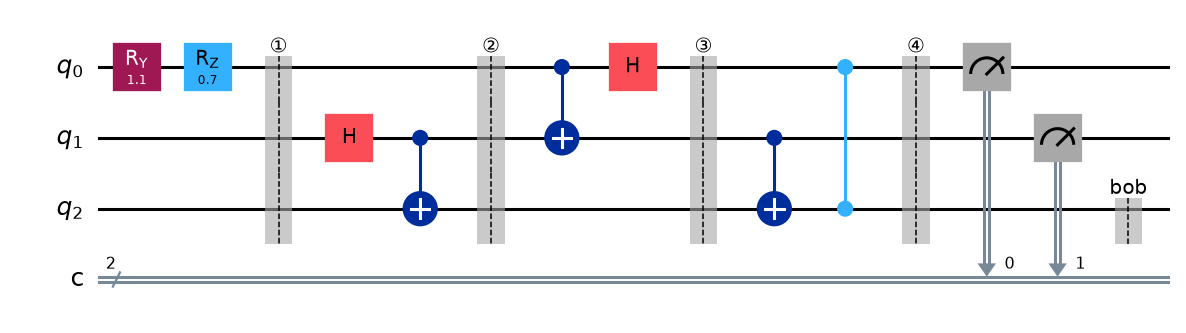

In [13]:
qc_dif = teleportacion(THETA, PHI, diferida=True)
qc_dif.save_density_matrix(qubits=[2], label="bob")
rho_dif = DensityMatrix(np.asarray(sim_dm.run(qc_dif, shots=8192).result().data(0)["bob"]))

print(f"{'variante':<34} {'fidelidad':>10} {'profundidad':>12}")
print(f"{'dinámica (if_test)':<34} {fidelidad_teleportada(THETA, PHI):>10.4f} "
      f"{teleportacion(THETA, PHI).depth():>12}")
print(f"{'diferida (CX/CZ)':<34} {state_fidelity(rho_dif, objetivo):>10.4f} "
      f"{qc_dif.depth():>12}")
print(f"{'dinámica + ruido FakeFez':<34} "
      f"{fidelidad_teleportada(THETA, PHI, ruido=True):>10.4f}")
display(qc_dif.draw("mpl", style="iqp", fold=-1))

### El estado, etapa por etapa

El deslizador recorre las barreras de la versión diferida (la dinámica no se
puede recorrer así, porque el `if_test` no tiene una matriz densidad bien
definida por etapa).

Lo que hay que mirar es el disco del **qubit 2, el de Bob**:

- en ① y ② está medio lleno y punteado: es la mitad de un par de Bell, no
  tiene información propia;
- en ③ sigue igual — **Alice ya hizo todo lo suyo y Bob no cambió nada**;
- recién en ④, después de las correcciones, el disco de Bob toma el aspecto
  del estado original: borde sólido, aguja en la fase correcta.

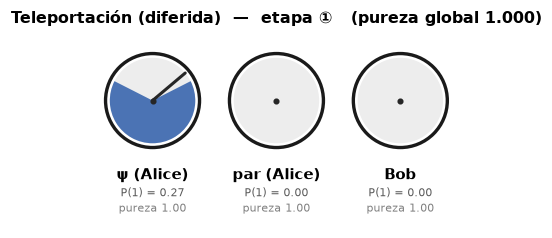

① el estado a teletransportar existe, en el qubit 0


SelectionSlider(continuous_update=False, description='etapa', layout=Layout(width='520px'), options=('①', '②',…

Output()

Output()

In [14]:
utils.explorador_de_etapas(
    teleportacion(THETA, PHI, diferida=True), titulo="Teleportación (diferida)",
    etiquetas_qubits=["ψ (Alice)", "par (Alice)", "Bob"],
    texto={"①": "① el estado a teletransportar existe, en el qubit 0",
           "②": "② par de Bell repartido: q1 y q2 se mezclan a la vez",
           "③": "③ Alice midió en base de Bell — el disco de Bob NO cambió",
           "④": "④ tras corregir: Bob tiene el estado original, puro y con su fase"})

---
# 3. Lo que la teleportación NO hace

Es el protocolo con peor prensa de la física, así que vamos a ser
explícitos.

**No clona.** El qubit de Alice queda medido, en $|0\rangle$ o $|1\rangle$:
$|\psi\rangle$ desaparece de su lado en el instante en que aparece del lado
de
Bob. Si no fuera así, el protocolo violaría el teorema de no-clonación, y de
hecho ese es el argumento de por qué la destrucción es **obligatoria**, no
un
efecto secundario.

**No transmite materia.** Lo que viaja es el *estado*. El qubit de Bob ya
estaba ahí, en su laboratorio, desde que repartieron el par.

**No es instantánea.** Sin los dos bits clásicos, Bob tiene $I/2$ — lo
medimos arriba. Los bits van por teléfono, radio o fibra: velocidad de la
luz,
como todo.

**No sirve para copiar un estado desconocido y estudiarlo.** Bob termina con
el mismo problema que tenía Alice: un qubit desconocido que solo puede medir
una vez.

### Para qué sirve de verdad

Es una **primitiva de arquitectura**, no un truco de salón:

- **Repetidores cuánticos**: la fibra atenúa fotones exponencialmente. La
  solución es repartir entrelazamiento en tramos cortos, hacer *entanglement
  swapping* (que es teleportar la mitad de un par usando otro par) y
    encadenar.
- **Computación por teleportación**: mover estados entre módulos de un
  procesador distribuido sin cables cuánticos entre ellos.
- **Compuertas por teleportación**: aplicar compuertas difíciles (como la
$T$)
  teletransportando a través de un estado preparado de antemano. Es la base
  de la *magic state distillation*, central en corrección de errores.

---
# 4. Hardware real

Dos experimentos con perfiles opuestos:

- **Superdensa**: sin mediciones intermedias, profundidad chica, dos qubits.
  Es de lo mejor que se puede correr en NISQ. Esperá diagonal de 0.90 o más.
- **Teleportación dinámica**: con medición a mitad de circuito y
  retroalimentación. Es el experimento exigente, y su resultado es una
    medida
  directa de cuánto cuesta el feed-forward en el chip.

In [15]:
if service is not None:
    print(f"{'backend':<16} {'qubits':>6} {'cola':>6}  {'estado':<10}")
    print("-" * 46)
    for b in service.backends(simulator=False):
        st = b.status()
        print(f"{b.name:<16} {b.num_qubits:>6} {st.pending_jobs:>6}  {st.status_msg:<10}")
else:
    print("sin autenticar")

sin autenticar


In [16]:
BACKEND_FIJO = None      # p.ej. "ibm_fez"; None = el menos ocupado

backend = None
if service is not None:
    backend = (service.backend(BACKEND_FIJO) if BACKEND_FIJO
               else service.least_busy(operational=True, simulator=False))
    st = backend.status()
    print(f"elegido: {backend.name}  ·  {st.status_msg}  ·  cola {st.pending_jobs}")
else:
    print("sin autenticar: no hay backend")

sin autenticar: no hay backend


In [17]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

SHOTS_HW = 4096
t_sd = t_tel = None
BASES_TOMO = ["X", "Y", "Z"]

if backend is not None:
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    t_sd = pm.run(circuitos_sd)
    circuitos_tel = ([teleportacion(THETA, PHI, tomografia=b) for b in BASES_TOMO] +
                     [teleportacion(THETA, PHI, corregir=False, tomografia=b)
                      for b in BASES_TOMO])
    t_tel = pm.run(circuitos_tel)

    print("=== Experimento A: codificación superdensa (4 mensajes) ===")
    costo_a = utils.informe_transpilacion(t_sd, shots=SHOTS_HW,
                                          nombre_backend=backend.name)
    print("\n=== Experimento B: teleportación + tomografía (6 circuitos) ===")
    costo_b = utils.informe_transpilacion(t_tel, shots=SHOTS_HW,
                                          nombre_backend=backend.name)
    print(f"\ntotal si mandás los dos: ~{costo_a + costo_b:.1f} s de QPU")
else:
    print("sin backend: nada que transpilar")

sin backend: nada que transpilar


### Experimento A — superdensa en el chip

Los cuatro mensajes en un solo job. La matriz de confusión 4×4 medida en
hardware es una figura que se explica sola, y el número que sale de ella
—bits por qubit enviado— o supera 1 o no supera 1. Si lo supera, hubo
entrelazamiento útil.

In [18]:
ENVIAR_SUPERDENSA = False    # ponerlo en True para gastar QPU

if ENVIAR_SUPERDENSA:
    from qiskit_ibm_runtime import SamplerV2

    job = SamplerV2(mode=backend).run(t_sd, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"03 superdensa: 4 mensajes, {SHOTS_HW} shots",
                        notebook="03", experimento="superdensa",
                        n_circuitos=len(t_sd), shots=SHOTS_HW,
                        orden=["00", "01", "10", "11"])
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


### Experimento B — teleportación con feed-forward

Seis circuitos: tomografía del qubit de Bob en $X$, $Y$ y $Z$, con
corrección
y sin ella. Con eso se reconstruye el vector de Bloch teletransportado y se
compara con el original.

Esperá una fidelidad bastante peor que la de la superdensa: la medición a
mitad de circuito y la retroalimentación clásica son las operaciones más
caras
que tiene el chip. Si sale por encima de **2/3**, el experimento fue
exitoso.

### De paso, pedimos el cronograma

`PEDIR_TIMING` activa un flag experimental que hace que IBM devuelva, en el
metadata del job, **el cronograma real con que el chip ejecutó el
circuito**:
cada instrucción con su canal, su tiempo de arranque y su duración.

No cuesta QPU extra —es metadata del mismo job— y da el único número que
este
notebook viene estimando sin medir: **cuánto tarda el chip entre que la
medición de Alice termina y la corrección de Bob arranca**. Durante ese
hueco
el qubit de Bob está decoherando.

El análisis completo de este dato está en `10_circuitos_dinamicos.ipynb`.

In [19]:
ENVIAR_TELEPORTACION = False   # ponerlo en True para gastar QPU

PEDIR_TIMING = True   # pedir el cronograma; no cuesta QPU extra

if ENVIAR_TELEPORTACION:
    from qiskit_ibm_runtime import SamplerV2

    sampler = SamplerV2(mode=backend)
    if PEDIR_TIMING:
        utils.pedir_timing(sampler.options)
        print("scheduler_timing activado")
    job = sampler.run(t_tel, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"03 teleportacion: tomografia XYZ con y sin correccion, {SHOTS_HW} shots",
                        notebook="03", experimento="teleportacion",
                        n_circuitos=len(t_tel), shots=SHOTS_HW,
                        theta=THETA, phi=PHI, timing=PEDIR_TIMING,
                        orden="corregida[X,Y,Z], sin_corregir[X,Y,Z]")
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


---
# 5. Recuperar y analizar

In [20]:
registros = utils.listar_jobs(filtro="03 ")

In [21]:
JOB_ID_SD = ""   # vacío = el último job de superdensa

if not JOB_ID_SD:
    reg = utils.ultimo_job(experimento="superdensa")
    JOB_ID_SD = reg["job_id"] if reg else ""
    if reg:
        print(f"último: {JOB_ID_SD}  ({reg['backend']}, {reg['fecha']})")

if JOB_ID_SD and service is not None:
    res = utils.recuperar(service, JOB_ID_SD).result()
    hw_sd = [utils.counts_de_resultado(res, i) for i in range(len(res))]
    M_hw, _ = matriz_confusion(hw_sd)

    fig, ejes = plt.subplots(1, 3, figsize=(13.5, 4))
    dibujar_confusion(M_ideal, claves, ejes[0], "Aer ideal")
    dibujar_confusion(M_ruido, claves, ejes[1], "FakeFez")
    dibujar_confusion(M_hw, claves, ejes[2], "hardware real")
    utils.layout(fig)
    plt.show()

    bits_hw = 2 * np.trace(M_hw) / 4
    print(f"acierto medio en hardware        : {np.trace(M_hw) / 4:.4f}")
    print(f"bits por qubit enviado           : {bits_hw:.4f}")
    print(f"cota clásica (Holevo, sin Bell)  : 1.0000")
    print("supera la cota:" , "SÍ" if bits_hw > 1 else "NO")
else:
    print("sin JOB_ID o sin autenticar: nada que recuperar")

sin JOB_ID o sin autenticar: nada que recuperar


In [22]:
JOB_ID_TEL = ""   # vacío = el último job de teleportación

if not JOB_ID_TEL:
    reg = utils.ultimo_job(experimento="teleportacion")
    JOB_ID_TEL = reg["job_id"] if reg else ""
    if reg:
        print(f"último: {JOB_ID_TEL}  ({reg['backend']}, {reg['fecha']})")

if JOB_ID_TEL and service is not None:
    res = utils.recuperar(service, JOB_ID_TEL).result()
    hw_tel = [utils.counts_de_resultado(res, i) for i in range(len(res))]

    def bloch_desde_tomografia(lista_counts):
        """<P> = P(0)-P(1) del bit 2 (el qubit de Bob), en cada base."""
        r = []
        for c in lista_counts:
            marg = utils.filtrar(c, {}, mantener=[2])
            n = sum(marg.values())
            r.append((marg.get("0", 0) - marg.get("1", 0)) / n)
        return np.array(r)

    r_hw = bloch_desde_tomografia(hw_tel[:3])
    r_hw_sin = bloch_desde_tomografia(hw_tel[3:6])
    rho_hw = DensityMatrix((np.eye(2) + sum(
        r_hw[i] * Pauli(p).to_matrix() for i, p in enumerate("XYZ"))) / 2)
    F_hw = state_fidelity(rho_hw, objetivo, validate=False)

    utils.bloch_plotly({"original": r_objetivo,
                        f"teleportado en el chip (F={F_hw:.3f})": r_hw,
                        "sin corregir (promedio de ramas)": r_hw_sin},
                       titulo="Teleportación en hardware real", tamano=520).show()

    print(f"vector original    : {np.round(r_objetivo, 4)}")
    print(f"vector recibido    : {np.round(r_hw, 4)}   |r| = {np.linalg.norm(r_hw):.4f}")
    print(f"sin corregir       : {np.round(r_hw_sin, 4)}   |r| = {np.linalg.norm(r_hw_sin):.4f}")
    print(f"\nfidelidad en hardware = {F_hw:.4f}")
    print(f"límite clásico        = {2/3:.4f}")
    print("supera el límite clásico:", "SÍ" if F_hw > 2 / 3 else "NO")
else:
    print("sin JOB_ID o sin autenticar: nada que recuperar")

sin JOB_ID o sin autenticar: nada que recuperar


### Cuánto costó el feed-forward, en nanosegundos

Si el job se mandó con `scheduler_timing`, acá sale el cronograma real:
dónde
está la medición de Alice, dónde arranca la corrección de Bob, y **cuánto
tiempo muerto hay en el medio**.

In [23]:
if JOB_ID_TEL and service is not None:
    filas_t, _ = utils.timing_de_resultado(res, 0)
    if filas_t:
        r_t = utils.resumen_timing(filas_t, dt=backend.dt)
        fig, ax = plt.subplots(figsize=(13, 0.45 * len(r_t["canales"]) + 2))
        utils.dibujar_timing(filas_t, dt=backend.dt, ax=ax,
                             titulo="Teleportación: el cronograma real del chip")
        utils.layout(fig)
        plt.show()
        print(f"duración del circuito : {r_t['duracion_total_s'] * 1e6:.2f} µs")
        print(f"medición              : {r_t.get('medicion_s', 0) * 1e9:.0f} ns")
        if "latencia_decision_s" in r_t:
            print(f"latencia de decisión  : "
                  f"{r_t['latencia_decision_s'] * 1e9:.0f} ns de tiempo muerto "
                  f"mientras el qubit de Bob decohera")
else:
    print("(se llena con un job mandado con PEDIR_TIMING)")

(se llena con un job mandado con PEDIR_TIMING)


---
## Qué quedó establecido

1. **Un par de Bell no transmite información por sí solo.** Los cuatro
discos
   de Bob son idénticos haga Alice lo que haga: el teorema de
     no-señalización,
   visto.
2. **Pero cambia lo que un qubit puede cargar.** Con entrelazamiento previo,
   un qubit lleva 2 bits en vez de 1, y eso viola la cota de Holevo *simple*
   sin violar ninguna ley.
3. **La teleportación es una reescritura de base seguida de dos bits.** El
   estado ya está del lado de Bob después de la medición de Alice, en una de
   cuatro versiones; los dos bits solo dicen cuál.
4. **Sin los bits, Bob tiene $I/2$.** El promedio de las cuatro ramas es la
   mezcla máxima. Ahí queda descartada la posibilidad de mandar señales
     superlumínicas.
5. **El original se destruye**, y tiene que ser así: si no, sería una
máquina
   de clonar.
6. La fidelidad **no depende del estado**, y superar $2/3$ es la firma de
que
   hubo entrelazamiento genuino en el medio.

**Siguiente:** `04_bb84.ipynb` — el mismo principio (medir destruye) puesto
a
trabajar para que dos personas compartan una clave que nadie más puede leer.